# CSE558 Data Science — Assignment 1, Question 1
**JL for K-means clustering**

This notebook implements the experiments specified in Q1(a)–Q1(e) on the preprocessed KDD Cup 1999 dataset. It first constructs the feature matrix, establishes the original-space K-means baseline, and then studies clustering quality, centre recovery, runtime, pairwise-distance preservation, and fixed-partition cost preservation under Gaussian random projection.

Run the notebook from top to bottom. The random seeds are fixed so that the experiment can be reproduced. Result tables are exported as CSV files in the notebook's working directory.

## Imports and dependencies
    Import NumPy and pandas for numerical computation and tabular summaries, `time` for measuring runtime, and Matplotlib/Seaborn for plots. The scikit-learn imports provide the KDD Cup 1999 dataset loader, K-means implementation, and Min-Max scaling.

In [1]:
# Numerical arrays, random number generation, and vectorised linear algebra
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

## Load the KDD Cup 1999 dataset
    Fetch the default 10% KDD Cup 1999 subset as a pandas DataFrame. `X` contains the 41 input attributes for each network connection, while `y` stores the original categorical connection labels. The labels are not used in the unsupervised K-means experiments.

In [2]:
kdd = fetch_kddcup99(
    subset=None,
    as_frame=True
)

X = kdd.data.copy()
y = kdd.target

print("Original dataset shape:", X.shape)
print("Target shape:", y.shape)

print(X.head())

Original dataset shape: (494021, 41)
Target shape: (494021,)
  duration protocol_type  service   flag src_bytes dst_bytes land  \
0        0        b'tcp'  b'http'  b'SF'       181      5450    0   
1        0        b'tcp'  b'http'  b'SF'       239       486    0   
2        0        b'tcp'  b'http'  b'SF'       235      1337    0   
3        0        b'tcp'  b'http'  b'SF'       219      1337    0   
4        0        b'tcp'  b'http'  b'SF'       217      2032    0   

  wrong_fragment urgent hot  ... dst_host_count dst_host_srv_count  \
0              0      0   0  ...              9                  9   
1              0      0   0  ...             19                 19   
2              0      0   0  ...             29                 29   
3              0      0   0  ...             39                 39   
4              0      0   0  ...             49                 49   

  dst_host_same_srv_rate dst_host_diff_srv_rate dst_host_same_src_port_rate  \
0                    1.0

## One-hot encode categorical attributes
    The three textual columns (`protocol_type`, `service`, and `flag`) are categorical, so they are expanded into indicator columns. All remaining numeric attributes are retained. `float32` reduces memory use for this large dataset.

In [3]:
categorical_features = [
    'protocol_type',
    'service',
    'flag'
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=np.float32
)

print("Shape after one-hot encoding:", X_encoded.shape)

Shape after one-hot encoding: (494021, 118)


## Remove constant features
    A feature with only one unique value cannot distinguish observations and contributes no useful variation to Euclidean distances. This cell keeps only columns with more than one distinct value.

In [4]:
X_encoded = X_encoded.loc[
    :,
    X_encoded.nunique() > 1
]

print("Shape after removing constant columns:", X_encoded.shape)

Shape after removing constant columns: (494021, 116)


## Scale features and construct the data matrix D
    Min-Max scaling maps each feature to the interval [0, 1]. The resulting matrix `D` is the common input to all Q1 experiments; its rows represent connections and its columns represent encoded/scaled features. The final shape gives the sample count n and feature count d.

In [5]:
scaler = MinMaxScaler()

D = scaler.fit_transform(X_encoded)

D = D.astype(np.float32)

print("Final D shape:", D.shape)
print("Number of samples (n):", D.shape[0])
print("Number of features (d):", D.shape[1])

Final D shape: (494021, 116)
Number of samples (n): 494021
Number of features (d): 116


## Q1(a) — Baseline K-means on the original data
    Run K-means directly on `D` with k=15 and five initializations (`n_init=5`). The K-means inertia is the sum of squared distances from each sample to its assigned cluster centre, i.e. the baseline clustering cost. The timer measures the baseline fit runtime. A fixed seed makes the clustering reproducible.

In [6]:
# Fix random seed for reproducibility
SEED = 42

# Start timer
start_time = time.time()

# Apply K-means on original dataset
kmeans_D = KMeans(
    n_clusters=15,
    n_init=5,
    random_state=SEED
)

kmeans_D.fit(D)

# End timer
end_time = time.time()

# Calculate clustering cost
baseline_cost = kmeans_D.inertia_

# Calculate execution time
baseline_time = end_time - start_time

print("Q1(a) Results")
print("----------------------------")
print("Number of clusters:", 15)
print("Baseline clustering cost:", baseline_cost)
print("Execution time:", baseline_time, "seconds")

Q1(a) Results
----------------------------
Number of clusters: 15
Baseline clustering cost: 54069.0390625
Execution time: 38.481769323349 seconds


### Q1(b) For each m ∈ {5,10,15,20,25}, draw A, compute E, run k-means on E and form B̂. Report cost(D, B̂ ) and the ratio cost(D, B̂ )/cost(D, B). Repeat this 5 times for each m, with a fresh A each time, and give the mean, smallest and largest ratio for each m in a table or bar graph. ### Comment on how the ratio changes with m, and on any ratio below 1.

## Helper function — Clustering cost in the original feature space
    This function evaluates a supplied set of centres against every row of `D`. It processes rows in chunks to avoid allocating a very large sample-by-centre distance matrix. For each row it calculates squared Euclidean distances to all centres, selects the nearest centre, and accumulates the minimum distances.

In [7]:
def calculate_clustering_cost(X, centers, chunk_size=10000):

    total_cost = 0.0

    for start in range(0, X.shape[0], chunk_size):

        end = min(start + chunk_size, X.shape[0])

        X_chunk = X[start:end]

        # Squared Euclidean distances
        distances = (
            np.sum(X_chunk ** 2, axis=1)[:, None]
            + np.sum(centers ** 2, axis=1)[None, :]
            - 2 * X_chunk @ centers.T
        )

        # Nearest-centre distance for every observation
        min_distances = np.min(
            np.maximum(distances, 0),
            axis=1
        )

        total_cost += np.sum(min_distances, dtype=np.float64)

    return total_cost

## Q1(b) — Gaussian projection and projected K-means
    For each requested projection dimension m, generate a fresh matrix A with independent Gaussian entries of variance 1/m. Project the data as E = D Aᵀ, then run K-means on E. The projected cluster labels are used to calculate cluster means from the original rows of D; these original-space means form B-hat. Evaluate their clustering cost on D and divide by the baseline cost. Five independent repetitions are performed for each m.

In [8]:
# Dimensions specified in the assignment
m_values = [5, 10, 15, 20, 25]

# Five independent repetitions
n_repeats = 5

# Store individual experiment results
results_q1b = []

# Fixed random seed
BASE_SEED = 42

for m in m_values:

    print(f"\nRunning experiments for m = {m}")

    for rep in range(n_repeats):

        print(f"Repetition {rep + 1}/5")

        # Generate a fresh random projection matrix
        rng = np.random.default_rng(
            BASE_SEED + m * 100 + rep
        )

        A = rng.normal(
            loc=0,
            scale=1 / np.sqrt(m),
            size=(m, D.shape[1])
        ).astype(np.float32)

        # Start timing
        start_time = time.time()

        # Project the original dataset
        E = D @ A.T

        # K-means on projected dataset
        kmeans_E = KMeans(
            n_clusters=15,
            n_init=5,
            random_state=BASE_SEED + rep
        )

        cluster_labels = kmeans_E.fit_predict(E)

        # Calculate centres using original D
        original_centers = np.zeros(
            (15, D.shape[1]),
            dtype=np.float64
        )

        for j in range(15):

            cluster_points = D[cluster_labels == j]

            original_centers[j] = np.mean(
                cluster_points,
                axis=0
            )

        # End timing
        end_time = time.time()

        elapsed_time = end_time - start_time

        # Calculate original-space clustering cost
        projected_cost = calculate_clustering_cost(
            D,
            original_centers
        )

        # Calculate ratio
        ratio = projected_cost / baseline_cost

        # Save results
        results_q1b.append({
            "m": m,
            "repetition": rep + 1,
            "projected_cost": projected_cost,
            "ratio": ratio,
            "time_seconds": elapsed_time
        })

        print("Cost:", projected_cost)
        print("Ratio:", ratio)
        print("Time:", elapsed_time)

        # Release memory
        del A, E, kmeans_E, cluster_labels


Running experiments for m = 5
Repetition 1/5
Cost: 60132.95760425494
Ratio: 1.1121514021128704
Time: 6.755735158920288
Repetition 2/5
Cost: 75411.1216635556
Ratio: 1.3947191030413109
Time: 6.25417160987854
Repetition 3/5
Cost: 63635.1265133304
Ratio: 1.1769235706181624
Time: 7.198230028152466
Repetition 4/5
Cost: 55157.00033144416
Ratio: 1.0201217052828802
Time: 6.067308187484741
Repetition 5/5
Cost: 62674.68613321883
Ratio: 1.1591603479538688
Time: 5.981809616088867

Running experiments for m = 10
Repetition 1/5
Cost: 59002.43107468539
Ratio: 1.0912424577489297
Time: 7.066460371017456
Repetition 2/5
Cost: 63379.01482434681
Ratio: 1.1721868175072454
Time: 6.731261491775513
Repetition 3/5
Cost: 53902.592879456635
Ratio: 0.9969215990161955
Time: 6.823503255844116
Repetition 4/5
Cost: 55868.56893972775
Ratio: 1.0332820761831485
Time: 7.003023862838745
Repetition 5/5
Cost: 56611.698364486816
Ratio: 1.0470261603696651
Time: 7.270798921585083

Running experiments for m = 15
Repetition 1/5
C

## Q1(b) — Summarise the five repetitions
    Convert the individual run records into a DataFrame and group by projection dimension. The mean, minimum, and maximum cost ratios describe the typical result and the observed run-to-run range for each m.

In [9]:
results_df = pd.DataFrame(results_q1b)

summary_q1b = results_df.groupby("m").agg(
    Mean_Ratio=("ratio", "mean"),
    Minimum_Ratio=("ratio", "min"),
    Maximum_Ratio=("ratio", "max")
).reset_index()

print("\nQ1(b) Summary")
print(summary_q1b.to_string(index=False))


Q1(b) Summary
 m  Mean_Ratio  Minimum_Ratio  Maximum_Ratio
 5    1.172615       1.020122       1.394719
10    1.068132       0.996922       1.172187
15    1.081016       0.961041       1.179501
20    1.021955       0.968033       1.106913
25    1.024777       1.007982       1.050958


## Q1(b) — Plot the clustering-cost ratio
    Plot the mean ratio against m, with asymmetric error bars extending to the minimum and maximum observed ratios. The horizontal line at 1 represents the original-data baseline: values near 1 indicate similar cost, while values above 1 indicate a higher cost than the baseline.

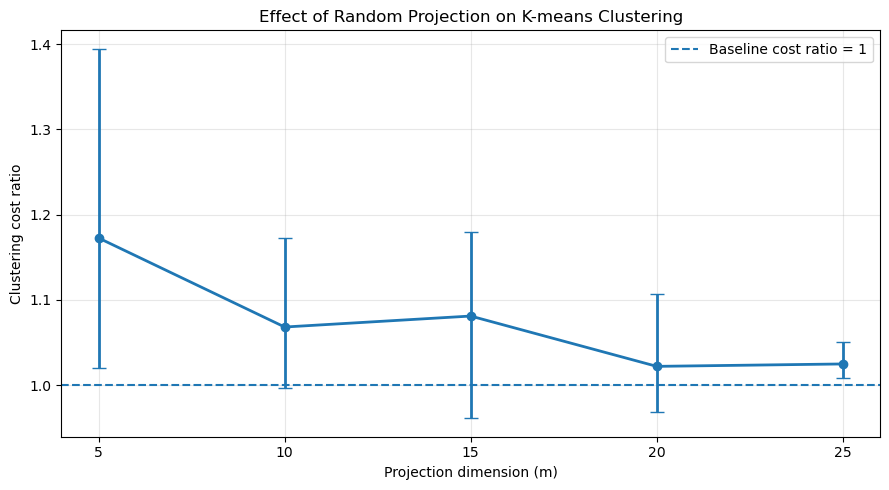

In [10]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    summary_q1b["m"],
    summary_q1b["Mean_Ratio"],
    yerr=[
        summary_q1b["Mean_Ratio"] -
        summary_q1b["Minimum_Ratio"],

        summary_q1b["Maximum_Ratio"] -
        summary_q1b["Mean_Ratio"]
    ],
    fmt='o-',
    capsize=5,
    linewidth=2
)

plt.axhline(
    y=1,
    linestyle='--',
    label='Baseline cost ratio = 1'
)

plt.xlabel("Projection dimension (m)")
plt.ylabel("Clustering cost ratio")
plt.title("Effect of Random Projection on K-means Clustering")
plt.xticks(m_values)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Q1(b) — Export results
    Save both the run-level measurements and the grouped summary as CSV files so the reported values can be checked or reused independently of the notebook.

In [11]:
results_df.to_csv("Q1b_Individual_Results.csv", index=False)
summary_q1b.to_csv("Q1b_Summary.csv", index=False)

### Q1(c) In the same runs, also map each centre a ∈ Rm found on E back to Rd as A +a,where A^+ is the pseudo-inverse of A (numpy.linalg.pinv); call these k centres B^+. Report cost(D, B^+)/cost(D, B) next to the ratio in (b). Which of B̂ and B^+ would you use?

## Q1(c) — Compare two ways to map projected centres back
    Recreate the same A matrices and projected K-means runs used in Q1(b), so both centre-recovery methods are evaluated on matching experiments. Method 1 computes each centre as the mean of the original-space points assigned to that projected cluster (B-hat). Method 2 maps the projected K-means centre through the Moore–Penrose pseudoinverse A⁺ (B-plus). Both centre sets are evaluated using the original-space clustering-cost function.

In [12]:
results_q1c = []

for m in m_values:

    print(f"\nRunning Q1(c) for m = {m}")

    for rep in range(n_repeats):

        rng = np.random.default_rng(
            BASE_SEED + m * 100 + rep
        )

        # Recreate the same projection matrix as Q1(b)
        A = rng.normal(
            loc=0,
            scale=1 / np.sqrt(m),
            size=(m, D.shape[1])
        ).astype(np.float32)

        # Project dataset
        E = D @ A.T

        # K-means
        kmeans_E = KMeans(
            n_clusters=15,
            n_init=5,
            random_state=BASE_SEED + rep
        )

        labels = kmeans_E.fit_predict(E)

        # ----------------------------------
        # METHOD 1: Original-space means
        # ----------------------------------

        B_hat = np.zeros(
            (15, D.shape[1]),
            dtype=np.float64
        )

        for j in range(15):
            B_hat[j] = D[labels == j].mean(axis=0)

        cost_Bhat = calculate_clustering_cost(D, B_hat)

        ratio_Bhat = cost_Bhat / baseline_cost

        # ----------------------------------
        # METHOD 2: Pseudo-inverse mapping
        # ----------------------------------

        A_pinv = np.linalg.pinv(A)

        # Map projected centres back to original space
        B_plus = (
            A_pinv @ kmeans_E.cluster_centers_.T
        ).T

        cost_Bplus = calculate_clustering_cost(D, B_plus)

        ratio_Bplus = cost_Bplus / baseline_cost

        # Store results
        results_q1c.append({
            "m": m,
            "repetition": rep + 1,
            "Cost_Bhat": cost_Bhat,
            "Ratio_Bhat": ratio_Bhat,
            "Cost_Bplus": cost_Bplus,
            "Ratio_Bplus": ratio_Bplus
        })

        print("Bhat ratio:", ratio_Bhat)
        print("Bplus ratio:", ratio_Bplus)

        del A, E, A_pinv, B_hat, B_plus


Running Q1(c) for m = 5
Bhat ratio: 1.1121514021128704
Bplus ratio: 76.80039395096786
Bhat ratio: 1.3947191030413109
Bplus ratio: 78.24029246632897
Bhat ratio: 1.1769235706181624
Bplus ratio: 81.32592560290942
Bhat ratio: 1.0201217052828802
Bplus ratio: 78.92246414917307
Bhat ratio: 1.1591603479538688
Bplus ratio: 77.98704267982544

Running Q1(c) for m = 10
Bhat ratio: 1.0912424577489297
Bplus ratio: 74.83097427226836
Bhat ratio: 1.1721868175072454
Bplus ratio: 73.41368546708306
Bhat ratio: 0.9969215990161955
Bplus ratio: 75.2179793253602
Bhat ratio: 1.0332820761831485
Bplus ratio: 77.18017351409021
Bhat ratio: 1.0470261603696651
Bplus ratio: 72.72439285712885

Running Q1(c) for m = 15
Bhat ratio: 0.9610414022403732
Bplus ratio: 72.83744723148621
Bhat ratio: 1.0886092773983942
Bplus ratio: 68.30102301859357
Bhat ratio: 1.1243425076086777
Bplus ratio: 70.30536066146288
Bhat ratio: 1.051587361163596
Bplus ratio: 73.2332856230064
Bhat ratio: 1.1795010536076431
Bplus ratio: 70.49334431740

## Q1(c) — Aggregate centre-recovery results
    Group the individual runs by m and calculate the mean baseline-normalised cost ratio for B-hat and B-plus. Lower ratios indicate a lower original-space clustering cost; the ideal reference is 1.

In [13]:
results_c_df = pd.DataFrame(results_q1c)

summary_q1c = results_c_df.groupby("m").agg(
    Mean_Bhat=("Ratio_Bhat", "mean"),
    Mean_Bplus=("Ratio_Bplus", "mean")
).reset_index()

print(summary_q1c.to_string(index=False))

 m  Mean_Bhat  Mean_Bplus
 5   1.172615   78.655224
10   1.068132   74.673441
15   1.081016   71.034092
20   1.021955   68.937455
25   1.024777   65.124313


## Q1(c) — Visual comparison
    Display the two mean cost ratios side by side for each projection dimension. The dashed horizontal line marks the baseline ratio of 1, making it easier to compare the quality of the two centre-recovery strategies.

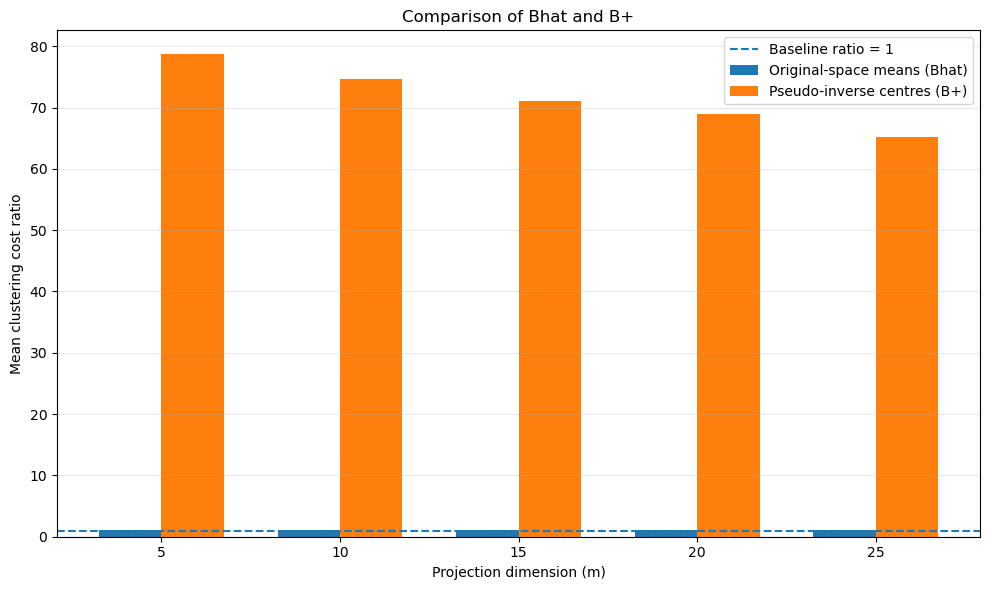

In [14]:
x = np.arange(len(m_values))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    summary_q1c["Mean_Bhat"],
    width,
    label="Original-space means (Bhat)"
)

plt.bar(
    x + width/2,
    summary_q1c["Mean_Bplus"],
    width,
    label="Pseudo-inverse centres (B+)"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Baseline ratio = 1"
)

plt.xticks(x, m_values)
plt.xlabel("Projection dimension (m)")
plt.ylabel("Mean clustering cost ratio")
plt.title("Comparison of Bhat and B+")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Q1(c) — Export results
    Save per-repetition results and the summary table for reproducibility and later reporting.

In [15]:
results_c_df.to_csv(
    "Q1c_Individual_Results.csv",
    index=False
)

summary_q1c.to_csv(
    "Q1c_Summary.csv",
    index=False
)

### Q1(d) For each m, report the wall-clock time of computing E plus running k-means on E, averaged over the 5 runs in (b). Plot these times against m, with the time from (a) as a horizontal line.

## Q1(d) — Measure projection plus K-means runtime
    For every m and each of five repetitions, generate A, form E = D Aᵀ, and fit K-means on E. The timer covers projection-matrix generation, data projection, and K-means fitting. The resulting measurements are compared with the full-data baseline time from Q1(a).

In [16]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

timing_results = []

for m in m_values:

    print(f"\nTiming experiments for m = {m}")

    for rep in range(5):

        rng = np.random.default_rng(
            BASE_SEED + m * 100 + rep
        )

        # Start timing
        start_time = time.perf_counter()

        # Generate random projection matrix
        A = rng.normal(
            0,
            1 / np.sqrt(m),
            size=(m, D.shape[1])
        ).astype(np.float32)

        # Project the dataset
        E = D @ A.T

        # Run K-means
        kmeans = KMeans(
            n_clusters=15,
            n_init=5,
            random_state=BASE_SEED + rep
        )

        kmeans.fit(E)

        # Stop timing
        end_time = time.perf_counter()

        elapsed = end_time - start_time

        timing_results.append({
            "m": m,
            "repetition": rep + 1,
            "time_seconds": elapsed
        })

        print(
            f"Repetition {rep + 1}: "
            f"{elapsed:.4f} seconds"
        )

        del A, E, kmeans


Timing experiments for m = 5
Repetition 1: 7.8976 seconds
Repetition 2: 7.3391 seconds
Repetition 3: 8.5362 seconds
Repetition 4: 7.1016 seconds
Repetition 5: 7.0674 seconds

Timing experiments for m = 10
Repetition 1: 8.0709 seconds
Repetition 2: 7.9622 seconds
Repetition 3: 7.0334 seconds
Repetition 4: 7.5947 seconds
Repetition 5: 6.8978 seconds

Timing experiments for m = 15
Repetition 1: 7.4162 seconds
Repetition 2: 7.2336 seconds
Repetition 3: 7.2612 seconds
Repetition 4: 7.4666 seconds
Repetition 5: 7.3540 seconds

Timing experiments for m = 20
Repetition 1: 8.2629 seconds
Repetition 2: 9.8701 seconds
Repetition 3: 9.3257 seconds
Repetition 4: 8.2045 seconds
Repetition 5: 7.7085 seconds

Timing experiments for m = 25
Repetition 1: 8.9986 seconds
Repetition 2: 8.8056 seconds
Repetition 3: 8.8779 seconds
Repetition 4: 8.6998 seconds
Repetition 5: 8.5643 seconds


## Q1(d) — Summarise runtimes
    Group the five measurements for each m and calculate the mean, minimum, and maximum runtime. This captures both typical computational cost and variation between runs.

In [17]:
timing_df = pd.DataFrame(timing_results)

timing_summary = timing_df.groupby("m").agg(
    Mean_Time=("time_seconds", "mean"),
    Min_Time=("time_seconds", "min"),
    Max_Time=("time_seconds", "max")
).reset_index()

print("\nQ1(d) Timing Summary")
print(timing_summary.to_string(index=False))


Q1(d) Timing Summary
 m  Mean_Time  Min_Time  Max_Time
 5   7.588393  7.067426  8.536203
10   7.511797  6.897805  8.070865
15   7.346336  7.233624  7.466595
20   8.674328  7.708483  9.870083
25   8.789238  8.564317  8.998622


## Q1(d) — Plot runtime comparison
    Plot the average projected-pipeline runtime against m. The horizontal reference line is the Q1(a) baseline runtime. This visualises whether dimension reduction offsets the cost of projection and clustering.

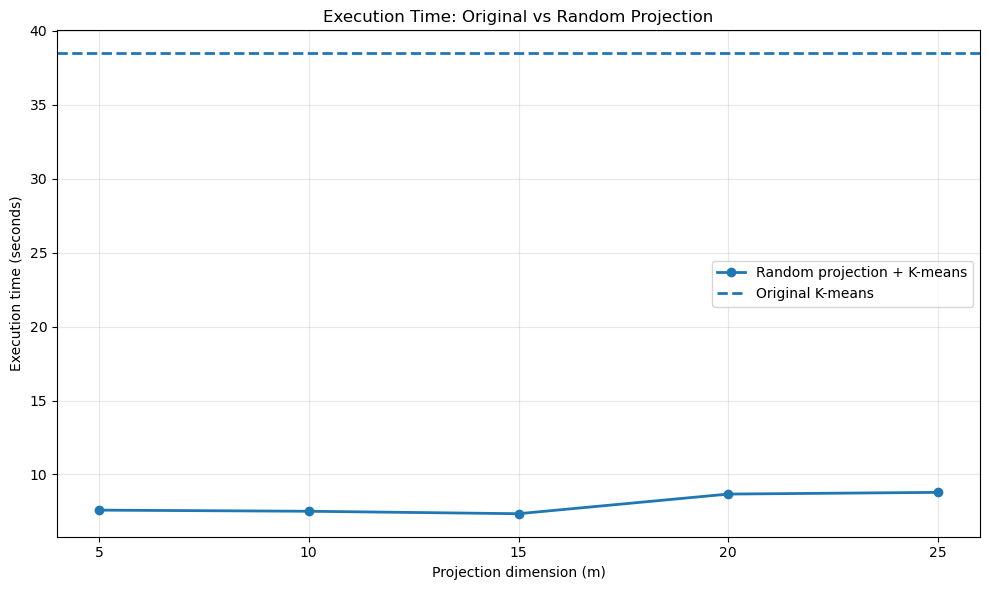

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(
    timing_summary["m"],
    timing_summary["Mean_Time"],
    marker='o',
    linewidth=2,
    label="Random projection + K-means"
)

plt.axhline(
    y=baseline_time,
    linestyle='--',
    linewidth=2,
    label="Original K-means"
)

plt.xlabel("Projection dimension (m)")
plt.ylabel("Execution time (seconds)")
plt.title("Execution Time: Original vs Random Projection")
plt.xticks(m_values)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Additional timing check
    This cell performs a separate single projection-and-K-means timing calculation. It is an auxiliary timing check; the official Q1(d) summary and plot are produced by the repeated experiment cells immediately above. The main reported timing results should therefore be taken from `timing_summary`.

In [19]:
# Generate A outside the timed section
A = rng.normal(
    0,
    1 / np.sqrt(m),
    size=(m, D.shape[1])
).astype(np.float32)

start_time = time.perf_counter()

E = D @ A.T

kmeans = KMeans(
    n_clusters=15,
    n_init=5,
    random_state=BASE_SEED + rep
)

kmeans.fit(E)

end_time = time.perf_counter()

elapsed = end_time - start_time

## Q1(d) — Export timing results
    Save individual timing observations and the per-dimension timing summary as CSV files.

In [20]:
timing_df.to_csv(
    "Q1d_Individual_Timings.csv",
    index=False
)

timing_summary.to_csv(
    "Q1d_Timing_Summary.csv",
    index=False
)

### Q1(e)  Pick 104 random pairs (i, l) with Di ≠ Dl , and use the same pairs for every m. For each m: (i) for one draw of A, compute ‖Ei −El‖22/‖Di − Dl‖22 for these pairs; (ii) for 20 independent draws of A, compute costE(CD)/costD(CD) for the clusters CD from (a). Show the ratios from (i) and from (ii) as box plots against m, in one figure. Which of the two has the smaller spread, and how does each change with m?

## Q1(e) — Select fixed random pairs of distinct observations
    Select 10,000 pairs of row indices once, using a fixed random seed. Pairs whose feature vectors are identical are rejected because their original squared distance would be zero and the distance ratio would be undefined. The same selected pairs are reused for every projection dimension, enabling a fair comparison across m.

In [21]:
# Number of random pairs
N_PAIRS = 10000

rng_pairs = np.random.default_rng(2026)

pair_i = []
pair_l = []

while len(pair_i) < N_PAIRS:

    remaining = N_PAIRS - len(pair_i)

    # Generate candidate pairs
    i = rng_pairs.integers(0, D.shape[0], size=remaining * 2)
    l = rng_pairs.integers(0, D.shape[0], size=remaining * 2)

    # Keep only pairs with different feature vectors
    valid = np.any(D[i] != D[l], axis=1)

    pair_i.extend(i[valid].tolist())
    pair_l.extend(l[valid].tolist())

# Retain exactly 10,000 pairs
pair_i = np.array(pair_i[:N_PAIRS])
pair_l = np.array(pair_l[:N_PAIRS])

print("Number of selected pairs:", len(pair_i))
print("Same feature vectors:", np.sum(
    np.all(D[pair_i] == D[pair_l], axis=1)
))

Number of selected pairs: 10000
Same feature vectors: 0


## Q1(e) — Compute original pairwise distances
    Calculate the difference vector for each selected pair and its squared Euclidean norm in the original feature space. These values are the denominators for the projected-to-original distance ratios.

In [22]:
# Original pairwise differences
pair_differences = (
    D[pair_i] - D[pair_l]
)

# Squared Euclidean distances
original_pair_distances = np.sum(
    pair_differences ** 2,
    axis=1
)

print("Original distances calculated:",
      len(original_pair_distances))

Original distances calculated: 10000


## Q1(e)(i) — Pairwise distance preservation
    For each m, draw one Gaussian projection matrix and project the selected pairwise difference vectors. Compute the ratio of projected squared distance to original squared distance for every pair. Ratios close to 1 indicate good distance preservation; the distribution's spread indicates how much preservation varies across pairs.

In [24]:
pairwise_results = []

for m in m_values:

    print(f"\nPairwise distance experiment: m = {m}")

    rng = np.random.default_rng(
        5000 + m
    )

    # Generate one random projection matrix
    A = rng.normal(
        0,
        1 / np.sqrt(m),
        size=(m, D.shape[1])
    ).astype(np.float32)

    # Project the selected pair differences
    projected_differences = pair_differences @ A.T

    # Calculate projected squared distances
    projected_pair_distances = np.sum(
        projected_differences ** 2,
        axis=1
    )

    # Calculate distance ratios
    ratios = (
        projected_pair_distances /
        original_pair_distances
    )

    pairwise_results.append({
        "m": m,
        "ratios": ratios
    })

    print("Mean ratio:", np.mean(ratios))
    print("Standard deviation:", np.std(ratios))

    del A, projected_differences


Pairwise distance experiment: m = 5
Mean ratio: 0.54791063
Standard deviation: 0.3705722

Pairwise distance experiment: m = 10
Mean ratio: 0.76966614
Standard deviation: 0.3573474

Pairwise distance experiment: m = 15
Mean ratio: 0.8710037
Standard deviation: 0.45843446

Pairwise distance experiment: m = 20
Mean ratio: 0.94163185
Standard deviation: 0.37691617

Pairwise distance experiment: m = 25
Mean ratio: 1.0872611
Standard deviation: 0.22378409


## Q1(e)(ii) — Fix the original K-means partition
    Retain the cluster labels obtained by K-means on the original data in Q1(a). The second experiment evaluates how well random projection preserves the cost of this fixed partition, rather than reclustering the projected data.

In [25]:
# Original cluster labels
original_labels = kmeans_D.labels_

# Original clustering cost
original_cluster_cost = baseline_cost

print("Original clustering cost:",
      original_cluster_cost)

print("Number of clusters:",
      len(np.unique(original_labels)))

Original clustering cost: 54069.0390625
Number of clusters: 15


## Helper function — Cost of a fixed partition
    Given data X and fixed cluster labels, calculate the within-cluster sum of squared distances to each cluster mean. The identity used here expresses this cost as total squared norm minus the sum of squared cluster sums divided by cluster sizes. This avoids explicitly constructing every cluster-centred row.

In [26]:
def fixed_partition_cost(X, labels, k=15):

    X = X.astype(np.float64)

    # Sum of observations in each cluster
    cluster_sums = np.zeros(
        (k, X.shape[1]),
        dtype=np.float64
    )

    np.add.at(
        cluster_sums,
        labels,
        X
    )

    # Number of observations in each cluster
    counts = np.bincount(
        labels,
        minlength=k
    )

    # Total sum of squared observations
    total_squared_norm = np.sum(X ** 2)

    # Sum of squared cluster means multiplied by cluster sizes
    explained_sum = np.sum(
        np.sum(cluster_sums ** 2, axis=1) / counts
    )

    return max(
        0.0,
        total_squared_norm - explained_sum
    )

## Q1(e)(ii) — Fixed-partition clustering-cost preservation
    For each m, generate 20 independent Gaussian projections. Evaluate the within-cluster cost of the original Q1(a) partition in projected space and divide it by the original-space cost of that same partition. The 20 ratios provide a distribution for comparison with the pairwise-distance ratios.

In [27]:
cluster_cost_results = []

N_DRAWS = 20

for m in m_values:

    print(f"\nClustering cost experiment: m = {m}")

    for rep in range(N_DRAWS):

        rng = np.random.default_rng(
            10000 + m * 100 + rep
        )

        # Generate fresh projection matrix
        A = rng.normal(
            0,
            1 / np.sqrt(m),
            size=(m, D.shape[1])
        ).astype(np.float32)

        # Project the entire dataset
        E = D @ A.T

        # Cost using original cluster assignments
        projected_cost = fixed_partition_cost(
            E,
            original_labels,
            k=15
        )

        # Calculate ratio
        ratio = (
            projected_cost /
            original_cluster_cost
        )

        cluster_cost_results.append({
            "m": m,
            "repetition": rep + 1,
            "projected_cost": projected_cost,
            "ratio": ratio
        })

        print(
            f"Repetition {rep + 1}: "
            f"Ratio = {ratio:.5f}"
        )

        del A, E


Clustering cost experiment: m = 5
Repetition 1: Ratio = 0.87075
Repetition 2: Ratio = 0.91893
Repetition 3: Ratio = 1.01777
Repetition 4: Ratio = 1.11904
Repetition 5: Ratio = 1.18927
Repetition 6: Ratio = 0.94207
Repetition 7: Ratio = 1.11907
Repetition 8: Ratio = 1.07027
Repetition 9: Ratio = 0.77316
Repetition 10: Ratio = 0.92319
Repetition 11: Ratio = 1.00028
Repetition 12: Ratio = 0.92680
Repetition 13: Ratio = 1.01629
Repetition 14: Ratio = 0.90403
Repetition 15: Ratio = 1.15730
Repetition 16: Ratio = 0.87024
Repetition 17: Ratio = 1.18130
Repetition 18: Ratio = 1.18819
Repetition 19: Ratio = 1.02579
Repetition 20: Ratio = 1.11145

Clustering cost experiment: m = 10
Repetition 1: Ratio = 1.03106
Repetition 2: Ratio = 0.90525
Repetition 3: Ratio = 1.25561
Repetition 4: Ratio = 1.09675
Repetition 5: Ratio = 0.82663
Repetition 6: Ratio = 1.07124
Repetition 7: Ratio = 0.83358
Repetition 8: Ratio = 0.98248
Repetition 9: Ratio = 0.99471
Repetition 10: Ratio = 1.01428
Repetition 11: Ra

## Q1(e) — Combined box-plot comparison
    Arrange pairwise-distance ratios and fixed-partition cost ratios side by side for each m. The reference line at 1 is ideal preservation. Different hatch patterns distinguish the two experiment types; the box widths and whiskers show their distributions.

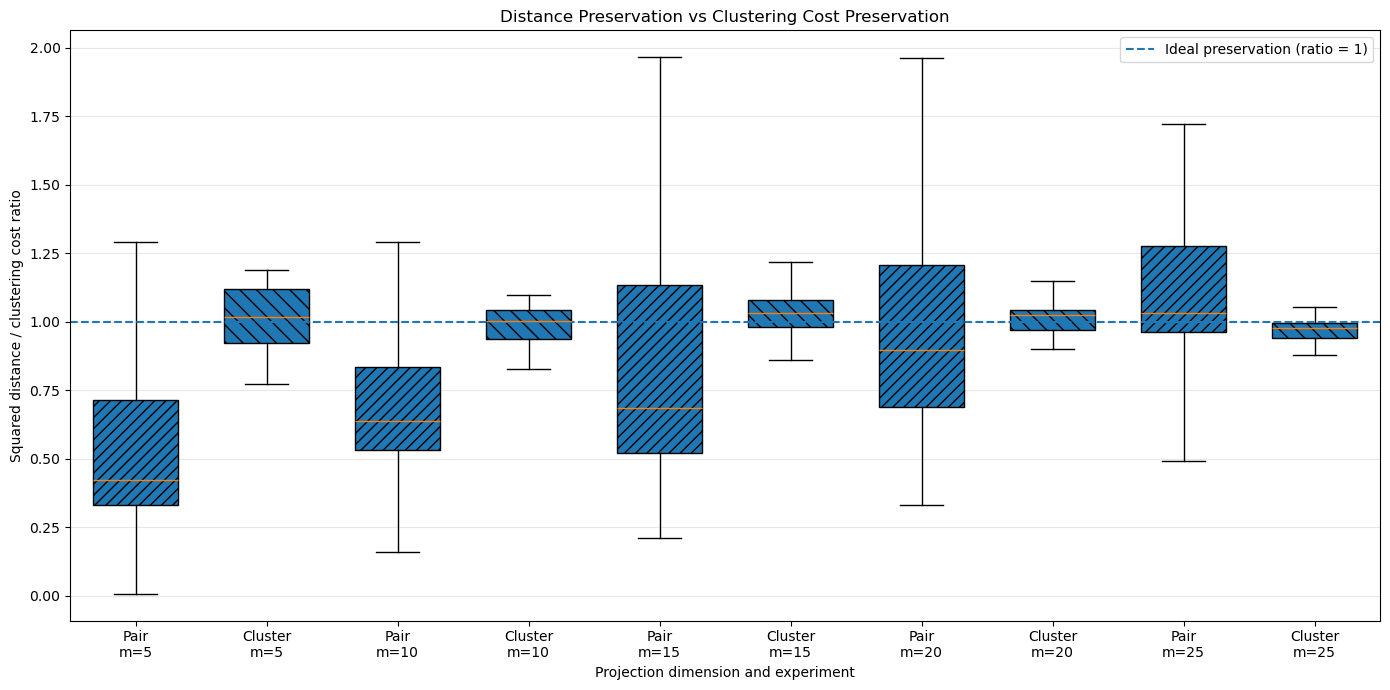

In [28]:
# Extract pairwise distance ratios
pair_data = [
    item["ratios"]
    for item in pairwise_results
]

# Extract clustering cost ratios
cluster_df = pd.DataFrame(cluster_cost_results)

cluster_data = [
    cluster_df.loc[
        cluster_df["m"] == m,
        "ratio"
    ].values
    for m in m_values
]

# Positions for both experiments
pair_positions = [2 * i + 1 for i in range(len(m_values))]
cluster_positions = [2 * i + 2 for i in range(len(m_values))]

plt.figure(figsize=(14, 7))

# Pairwise distance boxplots
bp1 = plt.boxplot(
    pair_data,
    positions=pair_positions,
    widths=0.65,
    patch_artist=True,
    showfliers=False
)

# Clustering cost boxplots
bp2 = plt.boxplot(
    cluster_data,
    positions=cluster_positions,
    widths=0.65,
    patch_artist=True,
    showfliers=False
)

# Distinguish the two experiment types using hatching
for box in bp1["boxes"]:
    box.set_hatch("///")

for box in bp2["boxes"]:
    box.set_hatch("\\\\")

# Reference line
plt.axhline(
    y=1,
    linestyle="--",
    label="Ideal preservation (ratio = 1)"
)

# X-axis labels
tick_positions = [
    position
    for pair in zip(pair_positions, cluster_positions)
    for position in pair
]

tick_labels = [
    label
    for m in m_values
    for label in [f"Pair\nm={m}", f"Cluster\nm={m}"]
]

plt.xticks(tick_positions, tick_labels)

plt.xlabel("Projection dimension and experiment")
plt.ylabel("Squared distance / clustering cost ratio")

plt.title(
    "Distance Preservation vs Clustering Cost Preservation"
)

plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Q1(e) — Numerical summary
    For each m, calculate the mean and standard deviation of the pairwise-distance ratios and of the fixed-partition clustering-cost ratios. These statistics complement the box plots and make the spread comparison explicit.

In [29]:
summary_q1e = []

for m in m_values:

    pair_ratios = next(
        item["ratios"]
        for item in pairwise_results
        if item["m"] == m
    )

    cluster_ratios = cluster_df.loc[
        cluster_df["m"] == m,
        "ratio"
    ].values

    summary_q1e.append({
        "m": m,

        "Pair_Mean": np.mean(pair_ratios),
        "Pair_Std": np.std(pair_ratios),

        "Cluster_Mean": np.mean(cluster_ratios),
        "Cluster_Std": np.std(cluster_ratios)
    })

summary_q1e_df = pd.DataFrame(summary_q1e)

print(summary_q1e_df.to_string(index=False))

 m  Pair_Mean  Pair_Std  Cluster_Mean  Cluster_Std
 5   0.547911  0.370572      1.016259     0.119564
10   0.769666  0.357347      0.990895     0.103349
15   0.871004  0.458434      1.033523     0.088322
20   0.941632  0.376916      1.020174     0.074238
25   1.087261  0.223784      0.965921     0.054369


## Q1(e) — Export all experiment outputs
    Export the summary, all 20 fixed-partition cost ratios per m, and all pairwise-distance ratios in long format. Keeping the detailed observations makes the plots and summary statistics auditable.

In [30]:
summary_q1e_df.to_csv(
    "Q1e_Summary.csv",
    index=False
)

cluster_df.to_csv(
    "Q1e_Cluster_Cost_Results.csv",
    index=False
)

# Save pairwise ratios in long format
pairwise_export = pd.DataFrame([
    {
        "m": item["m"],
        "pair_number": j + 1,
        "ratio": ratio
    }
    for item in pairwise_results
    for j, ratio in enumerate(item["ratios"])
])

pairwise_export.to_csv(
    "Q1e_Pairwise_Distance_Results.csv",
    index=False
)